
# OASIS INFOBYTE Data Science Internship
# Task 3: Car Price Prediction with Machine Learning

## 1. Introduction

Car price prediction is an important application of machine learning. The price of a used car depends on several factors, including its manufacturing year, brand, fuel type, transmission, kilometres driven, and ownership history.

In this project, we will analyze a used-car dataset and develop machine learning regression models to predict the selling price of cars. We will also explore the relationships between car features and selling prices to understand which factors influence the predictions.

## 2. Problem Statement

Estimating the correct price of a used car can be difficult because different vehicles have different features, conditions, and market values. This project aims to build a data-driven model that estimates used-car selling prices using historical vehicle data.

## 3. Objectives

- Load and inspect the used-car dataset.
- Clean missing values, duplicate records, and inconsistent data.
- Perform Exploratory Data Analysis (EDA).
- Create useful features such as car age and brand.
- Encode categorical variables and prepare data for modelling.
- Train and compare multiple regression algorithms.
- Evaluate models using MAE, RMSE, and R² score.
- Analyze feature importance and model prediction errors.
- Select the best-performing model based on evaluation results.
- Present findings, limitations, and conclusions.

## 4. Dataset Description

This project uses the CarDekho used-car dataset. The dataset is expected to contain information such as car name, manufacturing year, selling price, kilometres driven, fuel type, seller type, transmission, and ownership history.

The exact dataset structure and column names will be confirmed during data loading.

## 5. Tools and Technologies

- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Jupyter Notebook

## 6. Project Workflow

1. Data loading and inspection
2. Data cleaning and preprocessing
3. Exploratory Data Analysis
4. Feature engineering and encoding
5. Train-test split
6. Model training and comparison
7. Model evaluation and interpretation
8. Final findings and conclusion

## 7. Expected Outcome

The expected outcome is a machine learning model that estimates used-car selling prices from available vehicle features. The project will also identify important predictors and compare model performance using appropriate regression metrics.


In [1]:

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

from tkinter import Tk, filedialog

root = Tk()
root.withdraw()
root.attributes("-topmost", True)

file_path = filedialog.askopenfilename(
    title="Select CarDekho Dataset",
    filetypes=[("CSV files", "*.csv"), ("All files", "*.*")]
)

root.destroy()

if not file_path:
    raise ValueError("No file selected. Run this cell again.")

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Dataset shape: (4340, 8)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [3]:

print("Dataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", df.duplicated().sum())


Dataset shape: (4340, 8)

Column names: ['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   name           4340 non-null   str  
 1   year           4340 non-null   int64
 2   selling_price  4340 non-null   int64
 3   km_driven      4340 non-null   int64
 4   fuel           4340 non-null   str  
 5   seller_type    4340 non-null   str  
 6   transmission   4340 non-null   str  
 7   owner          4340 non-null   str  
dtypes: int64(3), str(5)
memory usage: 515.2 KB

Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
name,4340,1491,Maruti Swift Dzire VDI,69,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,4340.0,NaN,NaN,NaN,2013.090783,4.215344,1992.0,2011.0,2014.0,2016.0,2020.0
selling_price,4340.0,NaN,NaN,NaN,504127.311751,578548.736139,20000.0,208749.75,350000.0,600000.0,8900000.0
km_driven,4340.0,NaN,NaN,NaN,66215.777419,46644.102194,1.0,35000.0,60000.0,90000.0,806599.0
fuel,4340,5,Diesel,2153,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seller_type,4340,3,Individual,3244,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transmission,4340,2,Manual,3892,NaN,NaN,NaN,NaN,NaN,NaN,NaN
owner,4340,5,First Owner,2832,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing values:


,Missing Values
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0



Duplicate rows: 763


In [4]:

df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
)

rows_before = len(df)
duplicates_before = df.duplicated().sum()

df = df.drop_duplicates().copy()

print("Duplicate rows removed:", rows_before - len(df))
print("Dataset shape after cleaning:", df.shape)
print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))


Duplicate rows removed: 763
Dataset shape after cleaning: (3577, 8)

Missing values:


,Missing Values
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0


In [5]:

required_cols = [
    "name", "year", "selling_price", "km_driven",
    "fuel", "seller_type", "transmission", "owner"
]

missing_cols = [col for col in required_cols if col not in df.columns]

if missing_cols:
    raise ValueError(f"Missing expected columns: {missing_cols}")

for col in ["year", "selling_price", "km_driven"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(
    subset=["name", "year", "selling_price", "km_driven"]
).copy()

df = df[
    (df["year"] > 1900) &
    (df["selling_price"] > 0) &
    (df["km_driven"] >= 0)
].copy()

for col in ["name", "fuel", "seller_type", "transmission", "owner"]:
    df[col] = df[col].astype("string").str.strip()

for col in ["fuel", "seller_type", "transmission", "owner"]:
    df[col] = df[col].str.title()

df = df.dropna(subset=["name"]).copy()

print("Dataset shape after cleaning:", df.shape)
print("Remaining missing values:", df.isnull().sum().sum())
display(df.head())


Dataset shape after cleaning: (3577, 8)
Remaining missing values: 0


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [6]:

current_year = pd.Timestamp.today().year

df["car_age"] = current_year - df["year"]
df["brand"] = df["name"].str.split().str[0].str.title()

print("Unique brands:", df["brand"].nunique())
display(df[["name", "year", "brand", "car_age", "selling_price"]].head())


Unique brands: 29


,name,year,brand,car_age,selling_price
0,Maruti 800 AC,2007,Maruti,19,60000
1,Maruti Wagon R LXI Minor,2007,Maruti,19,135000
2,Hyundai Verna 1.6 SX,2012,Hyundai,14,600000
3,Datsun RediGO T Option,2017,Datsun,9,250000
4,Honda Amaze VX i-DTEC,2014,Honda,12,450000


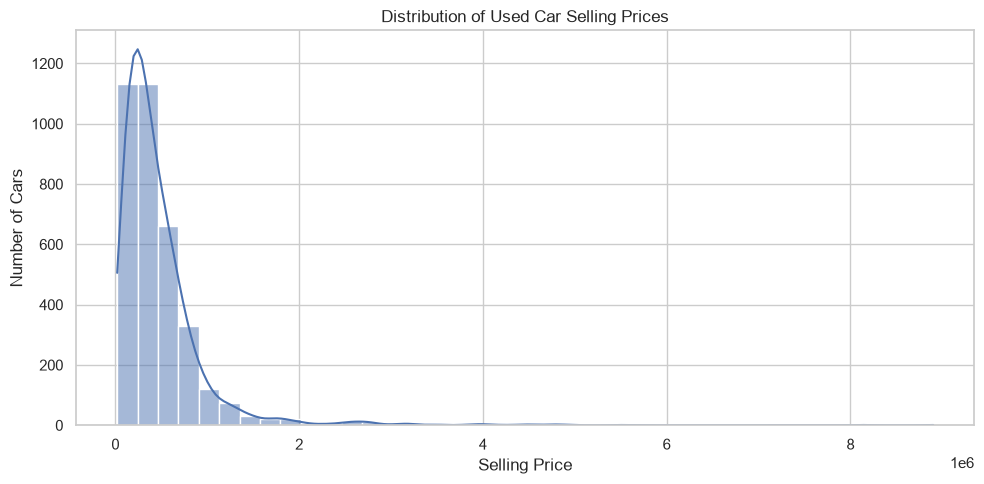

In [7]:

plt.figure(figsize=(10, 5))
sns.histplot(data=df, x="selling_price", bins=40, kde=True)
plt.title("Distribution of Used Car Selling Prices")
plt.xlabel("Selling Price")
plt.ylabel("Number of Cars")
plt.tight_layout()
plt.show()



### Observation: Selling Price Distribution

The histogram shows the distribution of used-car selling prices. It helps identify common price ranges, skewness, and unusually expensive vehicles. The actual distribution should be described based on the generated chart.


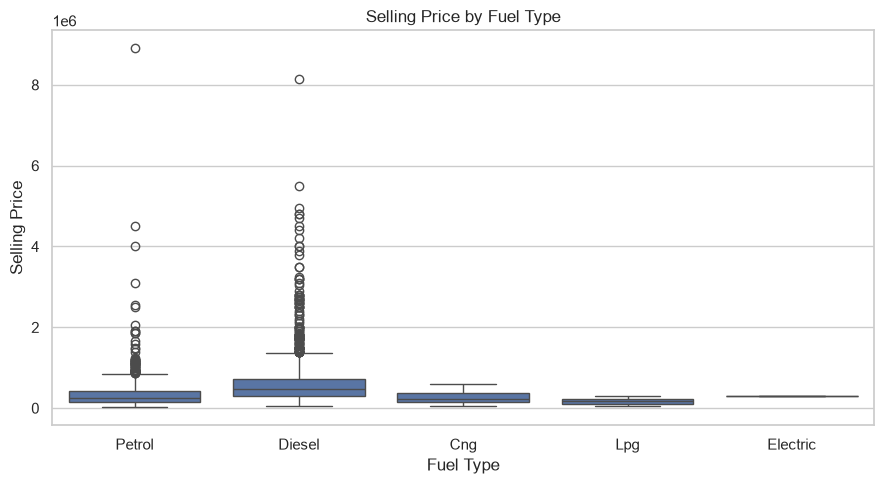

In [8]:

plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="fuel", y="selling_price")
plt.title("Selling Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price")
plt.tight_layout()
plt.show()



### Observation: Fuel Type and Price

The boxplot compares selling-price distributions across fuel types. Differences in medians and ranges suggest that fuel type may be associated with price. Car age, brand, mileage, and other characteristics may also explain these differences.


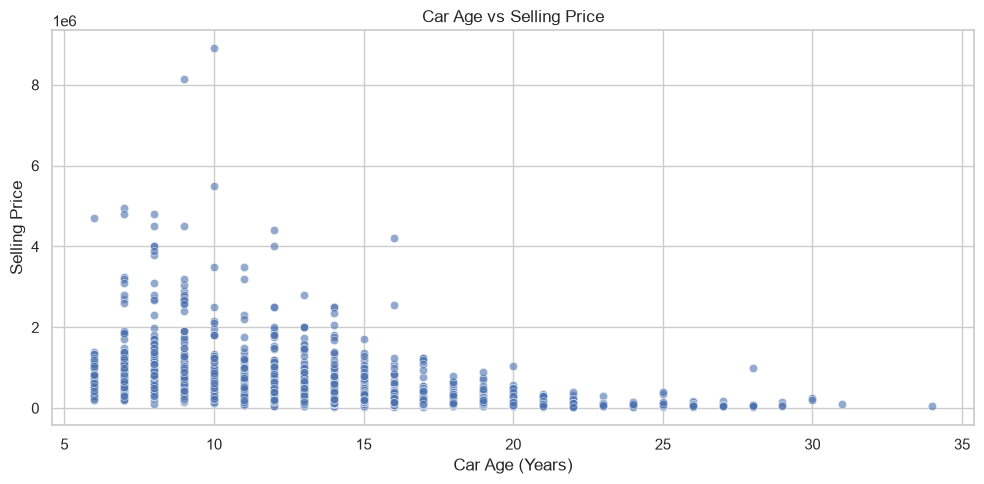

In [9]:

plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x="car_age", y="selling_price", alpha=0.6)
plt.title("Car Age vs Selling Price")
plt.xlabel("Car Age (Years)")
plt.ylabel("Selling Price")
plt.tight_layout()
plt.show()



### Observation: Car Age and Price

The scatterplot helps show whether older cars tend to sell for lower prices. The relationship may vary by brand, mileage, and vehicle type, so car age should not be treated as the only factor affecting price.


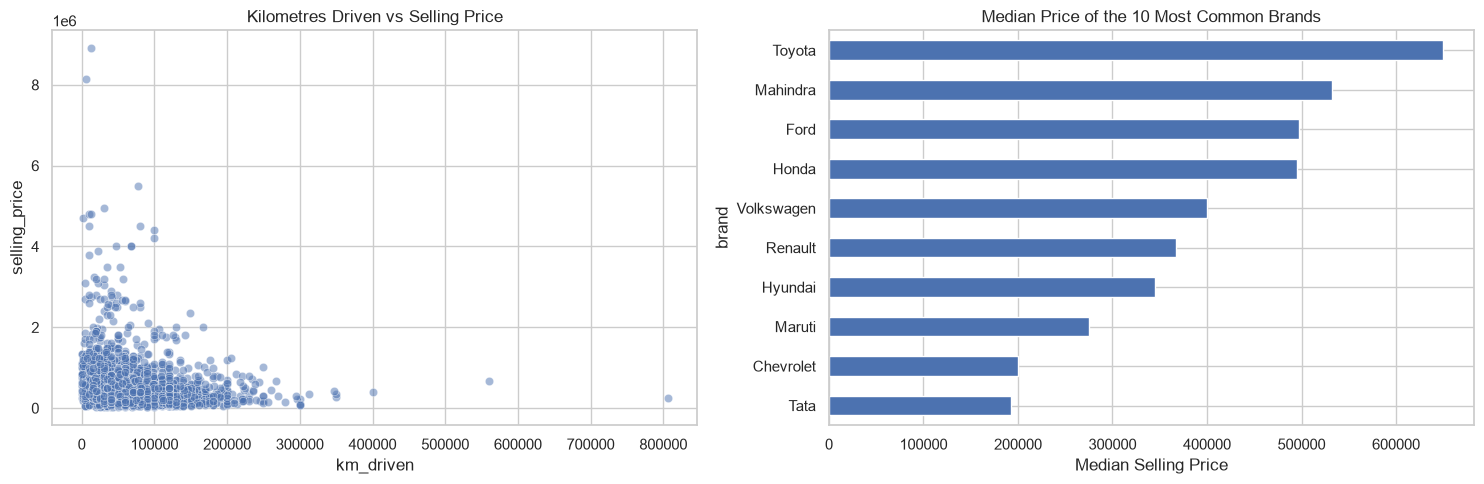

In [10]:

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.scatterplot(
    data=df, x="km_driven", y="selling_price",
    alpha=0.5, ax=axes[0]
)
axes[0].set_title("Kilometres Driven vs Selling Price")

top_brands = df["brand"].value_counts().head(10).index
brand_prices = (
    df[df["brand"].isin(top_brands)]
    .groupby("brand")["selling_price"]
    .median()
    .sort_values()
)

brand_prices.plot(kind="barh", ax=axes[1])
axes[1].set_title("Median Price of the 10 Most Common Brands")
axes[1].set_xlabel("Median Selling Price")

plt.tight_layout()
plt.show()



### Observation: Mileage and Brand

The mileage plot explores the relationship between kilometres driven and selling price. The brand chart compares median prices for frequently represented brands. These patterns may be useful for prediction, but they do not establish cause and effect.


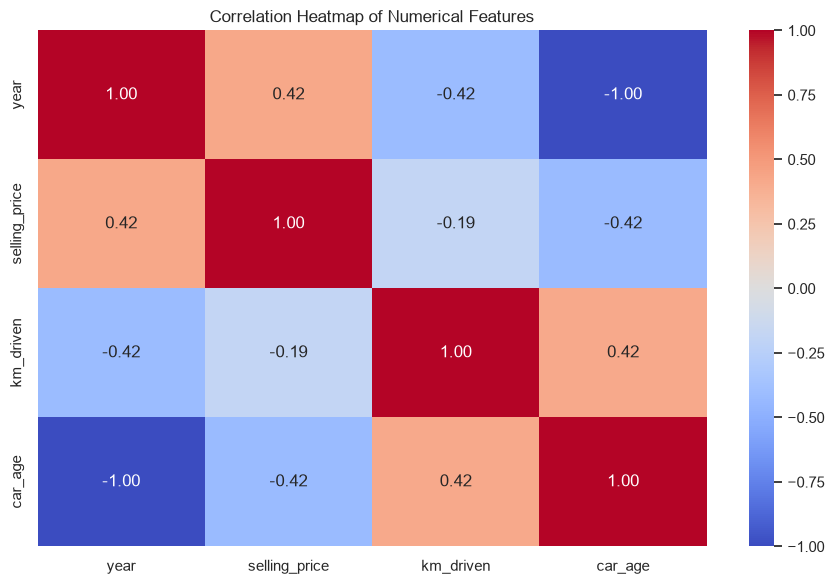

In [11]:

numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(9, 6))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)
plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()



### Observation: Correlation Analysis

The heatmap shows the direction and strength of linear relationships between numerical variables. Positive correlations indicate variables that tend to move together; negative correlations indicate variables that tend to move in opposite directions. Correlation does not prove causation.


In [12]:

feature_cols = [
    "car_age", "km_driven", "brand",
    "fuel", "seller_type", "transmission", "owner"
]

X = df[feature_cols].copy()
y = df["selling_price"].copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)
display(X.head())


Features shape: (3577, 7)
Target shape: (3577,)


,car_age,km_driven,brand,fuel,seller_type,transmission,owner
0,19,70000,Maruti,Petrol,Individual,Manual,First Owner
1,19,50000,Maruti,Petrol,Individual,Manual,First Owner
2,14,100000,Hyundai,Diesel,Individual,Manual,First Owner
3,9,46000,Datsun,Petrol,Individual,Manual,First Owner
4,12,141000,Honda,Diesel,Individual,Manual,Second Owner


In [13]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

numeric_features = ["car_age", "km_driven"]
categorical_features = [
    "brand", "fuel", "seller_type", "transmission", "owner"
]

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


Training rows: 2861
Testing rows: 716


In [14]:

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

trained_models = {}
predictions = {}
results = []

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    trained_models[name] = pipeline
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2 Score": r2_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results).sort_values("RMSE")
display(results_df)


,Model,MAE,RMSE,R2 Score
2,Random Forest,156381.187819,358751.267268,0.600468
3,Gradient Boosting,159394.415842,370774.919211,0.573239
0,Linear Regression,179642.129088,384722.830153,0.540527
1,Ridge Regression,180657.054370,386394.621979,0.536525


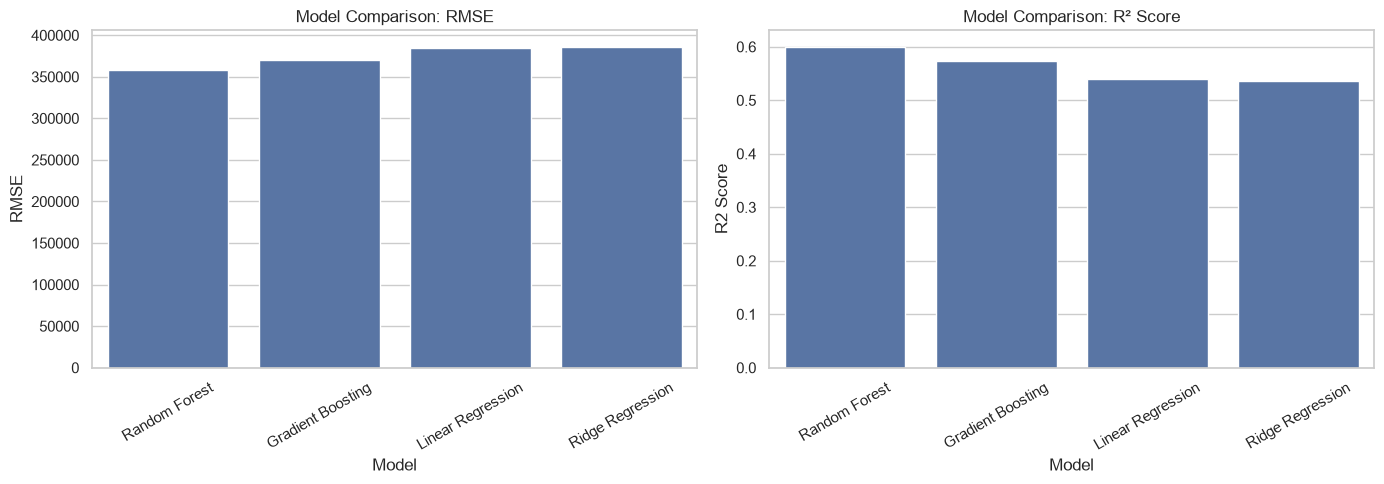

Best model by lowest RMSE: Random Forest


,Model,MAE,RMSE,R2 Score
2,Random Forest,156381.187819,358751.267268,0.600468


In [15]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=results_df, x="Model", y="RMSE", ax=axes[0])
axes[0].set_title("Model Comparison: RMSE")
axes[0].tick_params(axis="x", rotation=30)

sns.barplot(data=results_df, x="Model", y="R2 Score", ax=axes[1])
axes[1].set_title("Model Comparison: R² Score")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]
best_predictions = predictions[best_model_name]

print("Best model by lowest RMSE:", best_model_name)
display(results_df.iloc[[0]])



### Observation: Model Comparison

MAE measures average absolute prediction error. RMSE penalises larger errors more strongly, while R² measures how much variation in selling prices is explained by the model compared with a mean-prediction baseline.

The model with the lowest test-set RMSE is selected as the leading model in this comparison. Its MAE and R² should also be considered when assessing overall performance.


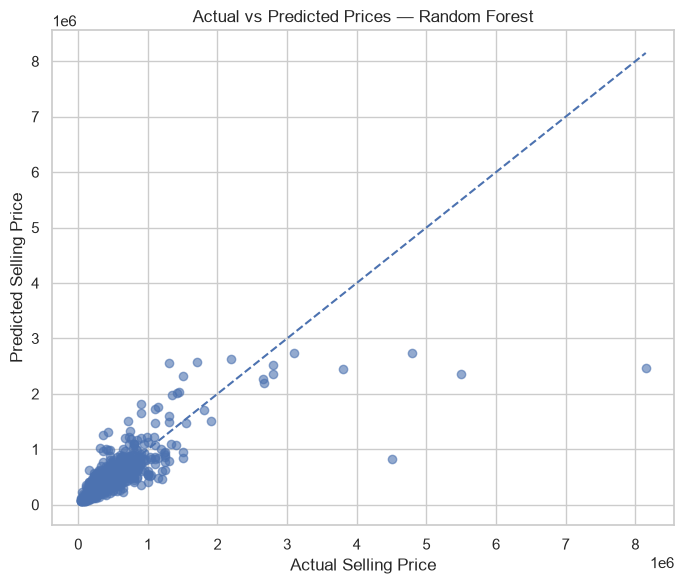

In [16]:

plt.figure(figsize=(7, 6))
plt.scatter(y_test, best_predictions, alpha=0.6)

lower = min(y_test.min(), best_predictions.min())
upper = max(y_test.max(), best_predictions.max())

plt.plot([lower, upper], [lower, upper], linestyle="--")
plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title(f"Actual vs Predicted Prices — {best_model_name}")
plt.tight_layout()
plt.show()


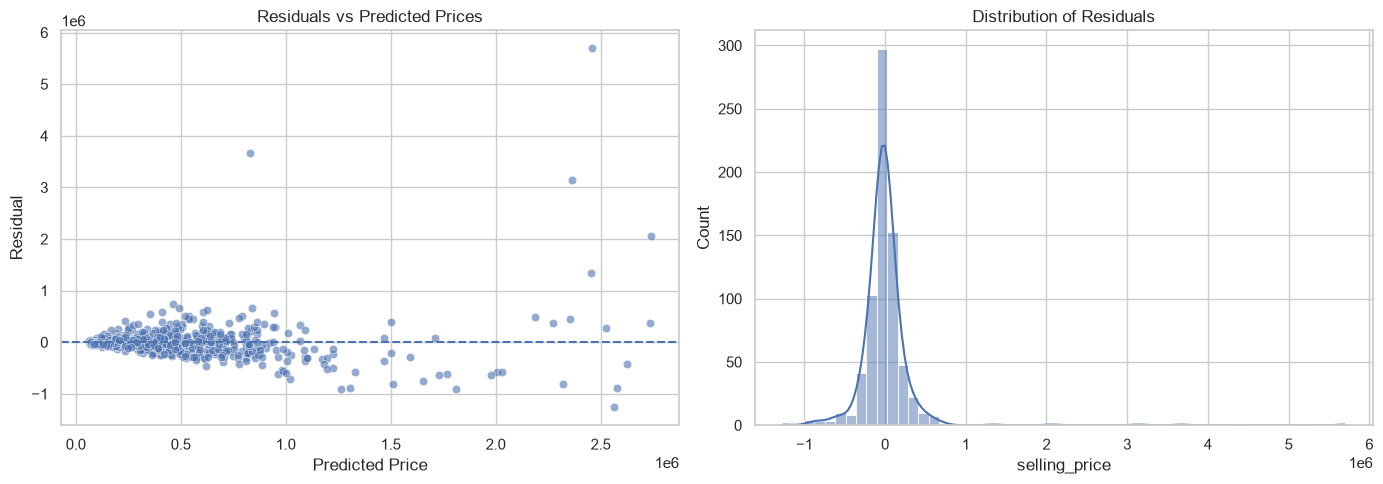

In [17]:

residuals = y_test - best_predictions

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    x=best_predictions, y=residuals,
    alpha=0.6, ax=axes[0]
)
axes[0].axhline(0, linestyle="--")
axes[0].set_title("Residuals vs Predicted Prices")
axes[0].set_xlabel("Predicted Price")
axes[0].set_ylabel("Residual")

sns.histplot(residuals, kde=True, ax=axes[1])
axes[1].set_title("Distribution of Residuals")

plt.tight_layout()
plt.show()



### Observation: Residual Analysis

Residuals are the differences between actual and predicted prices. A random scatter around zero is generally desirable. Visible patterns or larger errors for expensive vehicles may indicate that prediction accuracy varies across the price range.


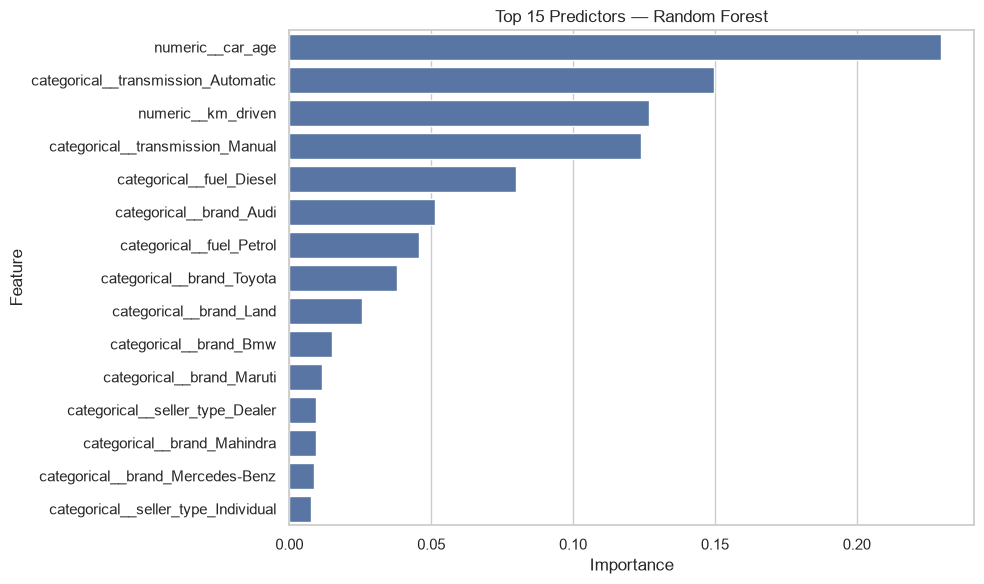

,Feature,Importance
0,numeric__car_age,0.229817
36,categorical__transmission_Automatic,0.149668
1,numeric__km_driven,0.126699
37,categorical__transmission_Manual,0.124007
30,categorical__fuel_Diesel,0.079859
3,categorical__brand_Audi,0.051318
32,categorical__fuel_Petrol,0.045607
26,categorical__brand_Toyota,0.037852
15,categorical__brand_Land,0.025620
4,categorical__brand_Bmw,0.014867


In [18]:

fitted_preprocessor = best_model.named_steps["preprocessor"]
fitted_estimator = best_model.named_steps["model"]

feature_names = fitted_preprocessor.get_feature_names_out()

if hasattr(fitted_estimator, "feature_importances_"):
    importance_values = fitted_estimator.feature_importances_
    importance_label = "Feature Importance"
elif hasattr(fitted_estimator, "coef_"):
    importance_values = np.abs(np.ravel(fitted_estimator.coef_))
    importance_label = "Absolute Coefficient"
else:
    raise ValueError("Selected model has no supported importance values.")

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
}).sort_values("Importance", ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df, x="Importance", y="Feature")
plt.title(f"Top 15 Predictors — {best_model_name}")
plt.tight_layout()
plt.show()

display(importance_df)


In [19]:

from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    best_model,
    X_train,
    y_train,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

cv_rmse = -cv_scores

print("Cross-validation RMSE scores:", np.round(cv_rmse, 2))
print("Mean CV RMSE:", round(cv_rmse.mean(), 2))
print("RMSE standard deviation:", round(cv_rmse.std(), 2))


Cross-validation RMSE scores: [271294.96 262490.52 410221.89 234894.36 294942.35]
Mean CV RMSE: 294768.82
RMSE standard deviation: 60839.63


In [20]:

best_row = results_df.loc[
    results_df["Model"] == best_model_name
].iloc[0]

print("=" * 40)
print("FINAL MODEL PERFORMANCE")
print("=" * 40)
print("Selected model:", best_model_name)
print(f"MAE: {best_row['MAE']:.2f}")
print(f"RMSE: {best_row['RMSE']:.2f}")
print(f"R² Score: {best_row['R2 Score']:.4f}")
print(f"Mean cross-validation RMSE: {cv_rmse.mean():.2f}")


FINAL MODEL PERFORMANCE
Selected model: Random Forest
MAE: 156381.19
RMSE: 358751.27
R² Score: 0.6005
Mean cross-validation RMSE: 294768.82


In [22]:

from pathlib import Path
from tkinter import Tk, filedialog
import joblib

root = Tk()
root.withdraw()
root.attributes("-topmost", True)

save_path = filedialog.asksaveasfilename(
    title="Save Cleaned Car Dataset",
    defaultextension=".csv",
    initialfile="cleaned_car_price_dataset.csv",
    filetypes=[("CSV files", "*.csv")]
)

root.destroy()

if save_path:
    save_path = Path(save_path)
    df.to_csv(save_path, index=False)

    model_path = save_path.parent / "best_car_price_model.joblib"
    joblib.dump(best_model, model_path)

    print("Cleaned dataset saved:", save_path)
    print("Model saved:", model_path)
else:
    print("Save cancelled. No files were saved.")


Cleaned dataset saved: C:\Users\hp\Desktop\OASIS INFOBYTE\AFTER CODE\3. cleaned_car_price_dataset.csv
Model saved: C:\Users\hp\Desktop\OASIS INFOBYTE\AFTER CODE\best_car_price_model.joblib


In [23]:

print("FINAL VERIFICATION")
print("-" * 35)
print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Models trained:", list(trained_models.keys()))
print("Best model:", best_model_name)
print("Feature importance rows:", len(importance_df))

assert len(df) > 0
assert len(trained_models) >= 2
assert len(results_df) >= 2
assert len(importance_df) > 0

print("\nBasic project checks passed.")


FINAL VERIFICATION
-----------------------------------
Dataset shape: (3577, 10)
Missing values: 0
Duplicate rows: 0
Models trained: ['Linear Regression', 'Ridge Regression', 'Random Forest', 'Gradient Boosting']
Best model: Random Forest
Feature importance rows: 15

Basic project checks passed.



## Conclusion

In this project, we developed a machine learning workflow for predicting used-car selling prices using the CarDekho dataset. We inspected and cleaned the data, engineered car age and brand features, and performed exploratory data analysis to understand price relationships.
We trained and compared Linear Regression, Ridge Regression, Random Forest, and Gradient Boosting models. Their performance was evaluated using MAE, RMSE, and R² score. We also examined actual-versus-predicted prices, residuals, and feature importance.
The leading model was selected based on its test-set RMSE, with cross-validation used as an additional reliability check.

### Limitations
- The dataset may not represent current prices in every market.
- Vehicle condition, location, service history, and current demand may not be available.
- Predictions are estimates and should not be treated as guaranteed selling prices.
- Correlation and feature importance do not prove causation.

### Future Improvements
- Include vehicle condition, location, and service-history data.
- Tune model hyperparameters using cross-validation.
- Compare errors across different price ranges.
- Validate the model on newer, independent data before real-world use.
